# Module 06: AI-Powered Smart Career Recommendation System

## Project Overview
This project uses machine learning to recommend suitable career paths based on a person's skills, interests, and technical knowledge.

## Objectives
- Explore and prepare a career recommendation dataset.
- Analyze skills and career choices.
- Train a machine learning classification model.
- Evaluate model performance.
- Recommend suitable career paths based on input skills.
- Visualize career recommendations and model results.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

## Project Workflow
1. Load and explore the dataset.
2. Clean and prepare the data.
3. Analyze career and skill patterns.
4. Train a machine learning model.
5. Evaluate the model.
6. Build a career recommendation function.
7. Visualize results and document conclusions.

In [1]:

# Import libraries for our career recommendation project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

print("All libraries imported successfully!")


All libraries imported successfully!


In [15]:

# Create a larger synthetic dataset for career recommendations

np.random.seed(42)

career_profiles = {
    "AI/ML Engineer":       [5, 5, 1, 3, 5, 3],
    "Data Scientist":       [4, 5, 1, 4, 5, 3],
    "Web Developer":        [1, 1, 5, 3, 4, 4],
    "Full Stack Developer": [2, 2, 5, 4, 4, 4],
    "UI/UX Designer":       [1, 1, 2, 4, 3, 5],
    "Data Analyst":         [3, 2, 2, 4, 4, 3]
}

records = []

for career, profile in career_profiles.items():
    for _ in range(20):
        skills = np.clip(
            np.array(profile) + np.random.randint(-1, 2, size=6),
            1, 5
        )
        records.append(list(skills) + [career])

columns = [
    "Python", "MachineLearning", "WebDevelopment",
    "Communication", "ProblemSolving", "Creativity", "Career"
]

df = pd.DataFrame(records, columns=columns)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Synthetic dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))
print("\nCareer counts:")
print(df["Career"].value_counts())


Synthetic dataset created successfully!
Dataset shape: (120, 7)


,Python,MachineLearning,WebDevelopment,Communication,ProblemSolving,Creativity,Career
0,1,1,5,4,4,3,Web Developer
1,2,1,4,4,3,4,Web Developer
2,4,4,1,4,5,4,AI/ML Engineer
3,1,1,4,4,5,3,Web Developer
4,5,4,1,5,5,4,Data Scientist
5,3,2,5,4,3,3,Full Stack Developer
6,3,3,5,5,4,3,Full Stack Developer
7,5,4,1,3,5,3,AI/ML Engineer
8,1,1,5,3,3,5,Web Developer
9,3,1,3,5,3,2,Data Analyst



Career counts:
Career
Web Developer           20
AI/ML Engineer          20
Data Scientist          20
Full Stack Developer    20
Data Analyst            20
UI/UX Designer          20
Name: count, dtype: int64


In [16]:

# Separate input features (X) and target (y)

X = df.drop("Career", axis=1)
y = df["Career"]

print("Input features (X):", X.shape)
print("Target (y):", y.shape)

print("\nCareer categories:")
print(y.unique())


Input features (X): (120, 6)
Target (y): (120,)

Career categories:
['Web Developer' 'AI/ML Engineer' 'Data Scientist' 'Full Stack Developer'
 'Data Analyst' 'UI/UX Designer']


In [17]:

# Split the updated dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (96, 6)
Testing features: (24, 6)
Training target: (96,)
Testing target: (24,)


In [18]:

# Train the model using the updated dataset

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training records:", len(X_train))


Model trained successfully!
Training records: 96


In [19]:

# Predict careers using the updated model

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Actual careers:", list(y_test))
print("Predicted careers:", list(y_pred))
print("Model Accuracy:", round(accuracy * 100, 2), "%")


Actual careers: ['Full Stack Developer', 'UI/UX Designer', 'Full Stack Developer', 'Web Developer', 'Data Scientist', 'AI/ML Engineer', 'Data Analyst', 'AI/ML Engineer', 'Data Scientist', 'Full Stack Developer', 'Web Developer', 'Web Developer', 'Data Analyst', 'Data Analyst', 'UI/UX Designer', 'Full Stack Developer', 'UI/UX Designer', 'Data Scientist', 'AI/ML Engineer', 'Data Analyst', 'Data Scientist', 'Web Developer', 'AI/ML Engineer', 'UI/UX Designer']
Predicted careers: ['Full Stack Developer', 'UI/UX Designer', 'Full Stack Developer', 'Full Stack Developer', 'Data Scientist', 'AI/ML Engineer', 'Data Analyst', 'AI/ML Engineer', 'Data Scientist', 'Web Developer', 'Web Developer', 'Web Developer', 'UI/UX Designer', 'Data Analyst', 'UI/UX Designer', 'Full Stack Developer', 'UI/UX Designer', 'AI/ML Engineer', 'AI/ML Engineer', 'Data Analyst', 'Data Scientist', 'Web Developer', 'Data Scientist', 'UI/UX Designer']
Model Accuracy: 79.17 %


In [20]:

# Evaluate the updated model

print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=sorted(y.unique()),
    zero_division=0
))


Classification Report:

                      precision    recall  f1-score   support

      AI/ML Engineer       0.75      0.75      0.75         4
        Data Analyst       1.00      0.75      0.86         4
      Data Scientist       0.75      0.75      0.75         4
Full Stack Developer       0.75      0.75      0.75         4
      UI/UX Designer       0.80      1.00      0.89         4
       Web Developer       0.75      0.75      0.75         4

            accuracy                           0.79        24
           macro avg       0.80      0.79      0.79        24
        weighted avg       0.80      0.79      0.79        24



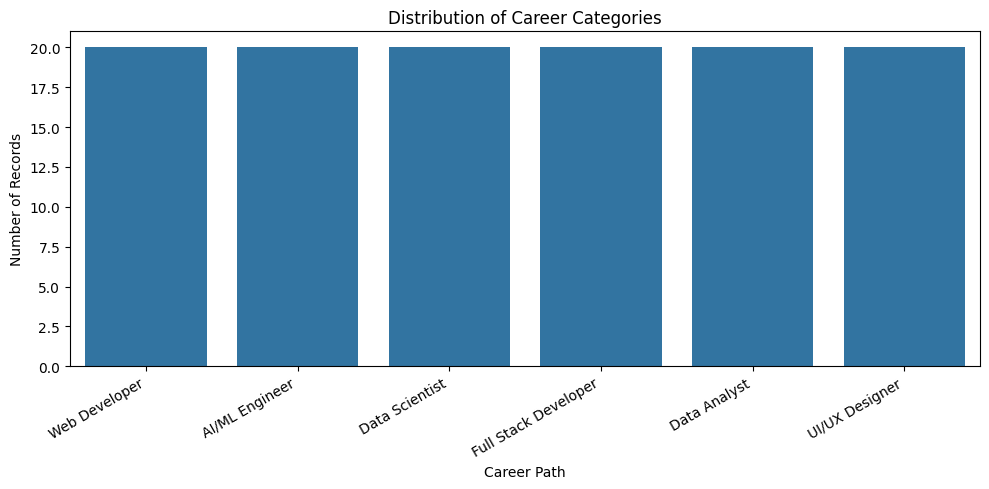

In [22]:

# Visualize career category distribution

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Career",
    order=df["Career"].value_counts().index
)

plt.title("Distribution of Career Categories")
plt.xlabel("Career Path")
plt.ylabel("Number of Records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [23]:

# Create a function to recommend a career

def recommend_career(python, machine_learning, web_development,
                    communication, problem_solving, creativity):

    user_skills = pd.DataFrame([{
        "Python": python,
        "MachineLearning": machine_learning,
        "WebDevelopment": web_development,
        "Communication": communication,
        "ProblemSolving": problem_solving,
        "Creativity": creativity
    }])

    prediction = model.predict(user_skills)

    return prediction[0]


career = recommend_career(5, 5, 1, 3, 5, 3)

print("Recommended career:", career)


Recommended career: AI/ML Engineer


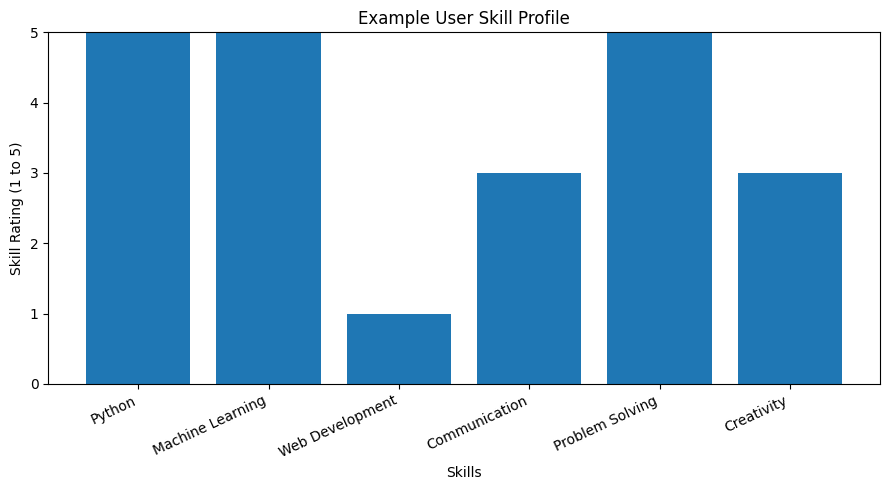

In [24]:

# Visualize the example user's skill ratings

user_skill_values = {
    "Python": 5,
    "Machine Learning": 5,
    "Web Development": 1,
    "Communication": 3,
    "Problem Solving": 5,
    "Creativity": 3
}

plt.figure(figsize=(9, 5))
plt.bar(user_skill_values.keys(), user_skill_values.values())

plt.title("Example User Skill Profile")
plt.xlabel("Skills")
plt.ylabel("Skill Rating (1 to 5)")
plt.ylim(0, 5)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [25]:

# Save updated model evaluation results

results = pd.DataFrame({
    "Metric": ["Accuracy"],
    "Score": [round(accuracy, 4)],
    "Percentage": [round(accuracy * 100, 2)]
})

results.to_csv("career_model_results.csv", index=False)

print("Updated model results saved successfully!")
display(results)


Updated model results saved successfully!


,Metric,Score,Percentage
0,Accuracy,0.7917,79.17


In [27]:

from google.colab import files

files.download("career_model_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>